# ZelaBairro — Big Data | Pipeline ETL + Apache Airflow

**FIAP · Global Solution 2026.2 · Big Data Architecture & Data Integration**

Este notebook reúne as duas etapas do módulo de dados do **ZelaBairro**:

- **Etapa 1 — Python + Pandas:** geração de uma base sintética, limpeza das ocorrências e construção de indicadores.
- **Etapa 2 — Apache Airflow:** transformação do mesmo ETL em um fluxo de **cinco tarefas orquestradas**, rodando temporariamente no Google Colab.

**Nota:** os dados são **100% sintéticos** e destinam-se exclusivamente a testes acadêmicos. Não representam reclamações reais, atendimento público ou reparos físicos. O campo `status` representa o processamento interno fictício do produto.


## 1. Justificativa da base de dados

O documento do grupo propõe uma entidade mínima de ocorrência com os campos `id`, `categoria`, `local`, `descricao`, `foto`, `status` e `data`. Como não há acesso autorizado a dados reais, usamos dados simulados, opção permitida pelo edital desde que a geração seja justificada e documentada.

**Regras transparentes de simulação (premissas didáticas, não estimativas do mundo real):**

- **240 ocorrências únicas**, distribuídas entre **01/08/2026 e 10/11/2026**, com `seed=2026` para reproduzir o mesmo resultado.
- Categorias relacionadas ao escopo do ZelaBairro: `sinalizacao` (40%), `lixeira` (25%), `banco` (20%) e `calcada` (15%). Esses pesos foram escolhidos para variar os agrupamentos e **não representam estatística oficial**.
- Locais fictícios, sem geolocalização: `Praça A`, `Praça B`, `Parque A`, `Rua A`, `Avenida A`.
- O status (`pendente`, `em_analise`, `em_andamento`, `concluida`) é atribuído com maior probabilidade de encerramento interno aos registros mais antigos. Esse comportamento é uma **hipótese de teste**, não um retrato de atendimento público.
- `foto` fica vazia: não existem arquivos de imagens associados aos registros artificiais.
- O campo extra `origem_dado = sintetico` identifica a procedência do registro.
- Inserimos **8 linhas duplicadas** e variações intencionais de caixa, acentuação e espaços em alguns campos para testar limpeza e deduplicação. Não inserimos erros que destruam a informação.

**Limites:** os indicadores mostram somente o comportamento deste conjunto de testes. Não servem para afirmar que um local real tem mais problemas ou que qualquer órgão consertou algo.

In [1]:
# Célula 1 — Bibliotecas padrão e configurações
from pathlib import Path
from datetime import date, timedelta
import json
import random
import unicodedata
import zipfile
import pandas as pd
from IPython.display import display

SEED = 2026
TOTAL_UNICOS = 240
BASE_DIR = Path('/content/zelabairro_etapa2')
PASTA_DADOS = BASE_DIR / 'dados'
PASTA_SAIDAS = BASE_DIR / 'saidas'
PASTA_DADOS.mkdir(parents=True, exist_ok=True)
PASTA_SAIDAS.mkdir(parents=True, exist_ok=True)

print('Ambiente preparado. Nenhuma instalação local é necessária no Google Colab.')

Ambiente preparado. Nenhuma instalação local é necessária no Google Colab.


In [2]:
# Célula 2 — Gerar dados fictícios de modo reproduzível
rng = random.Random(SEED)
categorias = ['sinalizacao', 'lixeira', 'banco', 'calcada']
pesos_categorias = [40, 25, 20, 15]
locais = ['Praça A', 'Praça B', 'Parque A', 'Rua A', 'Avenida A']
modelos_descricao = {
    'sinalizacao': ['Placa com texto pouco legível', 'Sinalização inclinada', 'Placa com suporte desgastado'],
    'lixeira': ['Lixeira sem tampa', 'Lixeira com estrutura danificada', 'Lixeira com peça solta'],
    'banco': ['Banco com assento danificado', 'Banco com parafuso aparente', 'Banco com encosto solto'],
    'calcada': ['Calçada com desnível', 'Trecho de calçada com piso solto', 'Calçada com obstáculo de passagem'],
}

inicio = date(2026, 8, 1)
fim = date(2026, 11, 10)
intervalo_dias = (fim - inicio).days
linhas = []
for n in range(1, TOTAL_UNICOS + 1):
    categoria = rng.choices(categorias, weights=pesos_categorias, k=1)[0]
    local = rng.choice(locais)
    dia = inicio + timedelta(days=rng.randint(0, intervalo_dias))
    idade = (fim - dia).days
    # Hipótese de teste: ocorrências mais antigas têm maior chance de encerramento interno.
    if idade >= 60:
        status = rng.choices(['pendente', 'em_analise', 'em_andamento', 'concluida'], [15, 20, 30, 35], k=1)[0]
    elif idade >= 30:
        status = rng.choices(['pendente', 'em_analise', 'em_andamento', 'concluida'], [30, 30, 25, 15], k=1)[0]
    else:
        status = rng.choices(['pendente', 'em_analise', 'em_andamento', 'concluida'], [50, 30, 15, 5], k=1)[0]
    linhas.append({
        'id': f'OC-{n:04d}',
        'categoria': categoria,
        'local': local,
        'descricao': rng.choice(modelos_descricao[categoria]),
        'foto': '',  # Não existem imagens reais/simuladas para anexar.
        'status': status,
        'data': dia.isoformat(),
        'origem_dado': 'sintetico',
    })

# Inserções de ruído controlado para tornar a limpeza demonstrável.
for pos in [2, 12, 27, 48, 96, 135, 180, 224]:
    linhas[pos]['categoria'] = ' SINALIZAÇÃO ' if linhas[pos]['categoria'] == 'sinalizacao' else ' ' + linhas[pos]['categoria'].upper() + ' '
for pos in [7, 36, 85, 122, 199]:
    linhas[pos]['local'] = '  ' + linhas[pos]['local'].upper() + ' '
for pos in [18, 51, 91, 151, 201]:
    linhas[pos]['status'] = ' ' + linhas[pos]['status'].replace('_', ' ').upper() + ' '
for pos in [21, 60, 101, 170]:
    linhas[pos]['data'] = date.fromisoformat(linhas[pos]['data']).strftime('%d/%m/%Y')

# Oito duplicatas exatas, para a ETL detectar pela chave ID.
for pos in [4, 24, 45, 78, 103, 141, 177, 230]:
    linhas.append(linhas[pos].copy())
rng.shuffle(linhas)

arquivo_bruto = PASTA_DADOS / 'zelabairro_ocorrencias_brutas.csv'
pd.DataFrame(linhas).to_csv(arquivo_bruto, index=False, encoding='utf-8-sig')
print('Base bruta criada:', arquivo_bruto)
print('Linhas brutas:', len(linhas), '| IDs previstos:', TOTAL_UNICOS, '| Linhas duplicadas adicionadas:', 8)

Base bruta criada: /content/zelabairro_etapa2/dados/zelabairro_ocorrencias_brutas.csv
Linhas brutas: 248 | IDs previstos: 240 | Linhas duplicadas adicionadas: 8


In [3]:
# Célula 3 — Ler e inspecionar os dados brutos
brutos = pd.read_csv(arquivo_bruto, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('Dimensão da base bruta:', brutos.shape)
print('IDs repetidos:', brutos.duplicated(subset=['id']).sum())
print('Campos disponíveis:', ', '.join(brutos.columns))
display(brutos.head(8))

Dimensão da base bruta: (248, 8)
IDs repetidos: 8
Campos disponíveis: id, categoria, local, descricao, foto, status, data, origem_dado


,id,categoria,local,descricao,foto,status,data,origem_dado
0,OC-0152,lixeira,Rua A,Lixeira sem tampa,,CONCLUIDA,2026-08-20,sintetico
1,OC-0040,lixeira,Praça B,Lixeira sem tampa,,em_andamento,2026-08-20,sintetico
2,OC-0167,calcada,Rua A,Calçada com obstáculo de passagem,,em_andamento,2026-09-18,sintetico
3,OC-0174,sinalizacao,Avenida A,Placa com texto pouco legível,,pendente,2026-09-02,sintetico
4,OC-0199,lixeira,Rua A,Lixeira sem tampa,,em_analise,2026-10-26,sintetico
5,OC-0209,sinalizacao,Avenida A,Sinalização inclinada,,concluida,2026-08-02,sintetico
6,OC-0086,lixeira,PRAÇA B,Lixeira sem tampa,,em_andamento,2026-08-21,sintetico
7,OC-0052,calcada,Parque A,Calçada com obstáculo de passagem,,EM ANALISE,2026-09-22,sintetico


## 2. ETL — limpeza e padronização

Nesta etapa o notebook:
1. Lê o arquivo bruto (Extract).
2. Remove duplicatas pelo `id`, padroniza grafia e datas e verifica valores válidos (Transform).
3. Salva a tabela tratada em CSV, pronta para consumo por outro componente do ZelaBairro (Load).

A deduplicação preserva a primeira linha de cada `id`; no gerador atual as duplicatas foram copiadas integralmente. Se um dado real trouxer versões conflitantes do mesmo ID, precisaríamos definir uma regra de atualização com o grupo.

In [4]:
# Célula 4 — Tratar os dados e auditar as regras

def normalizar_token(valor):
    texto = str(valor).strip().lower().replace(' ', '_')
    texto = ''.join(ch for ch in unicodedata.normalize('NFKD', texto) if not unicodedata.combining(ch))
    return texto

tratados = brutos.drop_duplicates(subset=['id'], keep='first').copy()
tratados['id'] = tratados['id'].str.strip()
tratados['categoria'] = tratados['categoria'].map(normalizar_token)
tratados['status'] = tratados['status'].map(normalizar_token)
tratados['local'] = tratados['local'].str.strip().str.title()
tratados['descricao'] = tratados['descricao'].str.strip()
tratados['foto'] = tratados['foto'].str.strip()
tratados['origem_dado'] = tratados['origem_dado'].map(normalizar_token)

# Aceita datas AAAA-MM-DD ou DD/MM/AAAA; retorna data ISO para integração.
data_iso = pd.to_datetime(tratados['data'], format='%Y-%m-%d', errors='coerce')
data_br = pd.to_datetime(tratados['data'], format='%d/%m/%Y', errors='coerce')
tratados['data'] = data_iso.fillna(data_br).dt.strftime('%Y-%m-%d')

categorias_validas = {'sinalizacao', 'lixeira', 'banco', 'calcada'}
status_validos = {'pendente', 'em_analise', 'em_andamento', 'concluida'}
assert tratados['categoria'].isin(categorias_validas).all(), 'Categoria inesperada'
assert tratados['status'].isin(status_validos).all(), 'Status inesperado'
assert tratados['data'].notna().all(), 'Data inválida'
assert tratados['id'].is_unique, 'IDs precisam ser únicos'
assert tratados['origem_dado'].eq('sintetico').all(), 'A origem sintética precisa estar identificada'

tratados = tratados.sort_values(['data', 'id']).reset_index(drop=True)
print('Linhas brutas:', len(brutos))
print('Duplicatas removidas:', len(brutos) - len(tratados))
print('Linhas tratadas:', len(tratados))
print('Período:', tratados['data'].min(), 'até', tratados['data'].max())
display(tratados.head(8))

Linhas brutas: 248
Duplicatas removidas: 8
Linhas tratadas: 240
Período: 2026-08-02 até 2026-11-10


,id,categoria,local,descricao,foto,status,data,origem_dado
0,OC-0036,banco,Rua A,Banco com parafuso aparente,,concluida,2026-08-02,sintetico
1,OC-0209,sinalizacao,Avenida A,Sinalização inclinada,,concluida,2026-08-02,sintetico
2,OC-0062,sinalizacao,Praça B,Placa com texto pouco legível,,em_analise,2026-08-03,sintetico
3,OC-0064,lixeira,Avenida A,Lixeira com estrutura danificada,,concluida,2026-08-05,sintetico
4,OC-0189,sinalizacao,Praça B,Placa com suporte desgastado,,em_analise,2026-08-05,sintetico
5,OC-0198,lixeira,Praça B,Lixeira com estrutura danificada,,pendente,2026-08-05,sintetico
6,OC-0091,lixeira,Avenida A,Lixeira com estrutura danificada,,concluida,2026-08-06,sintetico
7,OC-0135,sinalizacao,Avenida A,Placa com texto pouco legível,,concluida,2026-08-07,sintetico


In [5]:
# Célula 5 — Criar indicadores para o painel
por_categoria = tratados.groupby('categoria').size().reset_index(name='quantidade')
por_local = tratados.groupby('local').size().reset_index(name='quantidade')
por_status = tratados.groupby('status').size().reset_index(name='quantidade')
por_categoria_status = tratados.groupby(['categoria', 'status']).size().reset_index(name='quantidade')

assert por_categoria['quantidade'].sum() == len(tratados)
assert por_local['quantidade'].sum() == len(tratados)
assert por_status['quantidade'].sum() == len(tratados)

print('TOTAL DE OCORRÊNCIAS FICTÍCIAS:', len(tratados))
print('\nOCORRÊNCIAS POR CATEGORIA')
display(por_categoria)
print('\nOCORRÊNCIAS POR LOCAL')
display(por_local)
print('\nOCORRÊNCIAS POR STATUS INTERNO')
display(por_status)

TOTAL DE OCORRÊNCIAS FICTÍCIAS: 240

OCORRÊNCIAS POR CATEGORIA


,categoria,quantidade
0,banco,42
1,calcada,30
2,lixeira,67
3,sinalizacao,101



OCORRÊNCIAS POR LOCAL


,local,quantidade
0,Avenida A,61
1,Parque A,48
2,Praça A,42
3,Praça B,38
4,Rua A,51



OCORRÊNCIAS POR STATUS INTERNO


,status,quantidade
0,concluida,56
1,em_analise,59
2,em_andamento,52
3,pendente,73


In [6]:
# Célula 6 — Entregar os arquivos que poderão ser consumidos pelo MVP
tratados.to_csv(PASTA_SAIDAS / 'ocorrencias_tratadas.csv', index=False, encoding='utf-8-sig')
por_categoria.to_csv(PASTA_SAIDAS / 'indicadores_categoria.csv', index=False, encoding='utf-8-sig')
por_local.to_csv(PASTA_SAIDAS / 'indicadores_local.csv', index=False, encoding='utf-8-sig')
por_status.to_csv(PASTA_SAIDAS / 'indicadores_status.csv', index=False, encoding='utf-8-sig')
por_categoria_status.to_csv(PASTA_SAIDAS / 'indicadores_categoria_status.csv', index=False, encoding='utf-8-sig')

payload = {
    'produto': 'ZelaBairro',
    'origem_dado': 'sintetico',
    'territorio': 'locais ficticios (piloto ainda nao definido)',
    'periodo_inicio': tratados['data'].min(),
    'periodo_fim': tratados['data'].max(),
    'total_ocorrencias': int(len(tratados)),
    'por_categoria': por_categoria.to_dict(orient='records'),
    'por_local': por_local.to_dict(orient='records'),
    'por_status': por_status.to_dict(orient='records'),
}
(PASTA_SAIDAS / 'indicadores.json').write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')

with zipfile.ZipFile('zelabairro_etapa1_resultados.zip', mode='w', compression=zipfile.ZIP_DEFLATED) as pacote:
    for arquivo in sorted(PASTA_DADOS.glob('*.csv')):
        pacote.write(arquivo, arcname=f'dados/{arquivo.name}')
    for arquivo in sorted(PASTA_SAIDAS.glob('*')):
        pacote.write(arquivo, arcname=f'saidas/{arquivo.name}')
print('Arquivos gerados em:', PASTA_DADOS, 'e', PASTA_SAIDAS)
print('Pacote gerado: zelabairro_etapa1_resultados.zip')
print('Etapa 1 concluída: arquivos e indicadores gerados. A seguir, Airflow orquestra as mesmas operações.')

Arquivos gerados em: /content/zelabairro_etapa2/dados e /content/zelabairro_etapa2/saidas
Pacote gerado: zelabairro_etapa1_resultados.zip
Etapa 1 concluída: arquivos e indicadores gerados. A seguir, Airflow orquestra as mesmas operações.


---

# Etapa 2 — Orquestração com Apache Airflow

Agora, **no mesmo Colab**, criamos os arquivos Python da DAG e executamos o ETL de forma orquestrada. A DAG recria os mesmos dados sintéticos de maneira reproduzível, podendo ser executada novamente. Isso não altera o escopo definido pelo grupo.

## 1. Preparar a pasta do projeto

In [7]:
from pathlib import Path
import os, sys

DAGS_DIR = BASE_DIR / 'dags'
DAGS_DIR.mkdir(parents=True, exist_ok=True)
(BASE_DIR / 'dados').mkdir(exist_ok=True)
(BASE_DIR / 'saidas').mkdir(exist_ok=True)
print('Pasta preparada:', BASE_DIR)
print('Versão do Python:', sys.version.split()[0])

Pasta preparada: /content/zelabairro_etapa2
Versão do Python: 3.13.18


## 2. Criar os dois scripts Python usados pela DAG

O primeiro contém o processamento da Etapa 1, agora organizado em funções. O segundo contém a DAG e as cinco tarefas Airflow.

In [8]:
%%writefile /content/zelabairro_etapa2/dags/zelabairro_pipeline.py
"""ETL do ZelaBairro: geração reproduzível de dados sintéticos e indicadores.

Dados não oficiais; status de processamento interno, sem vínculo com prefeitura.
Artefatos de dados são trocados via arquivos, não DataFrames no XCom do Airflow.
"""
from datetime import date, timedelta
from pathlib import Path
import json
import random
import unicodedata
import pandas as pd

SEED = 2026
TOTAL_UNICOS = 240
CATEGORIAS = ['sinalizacao', 'lixeira', 'banco', 'calcada']
STATUS = ['pendente', 'em_analise', 'em_andamento', 'concluida']
CAMPOS = ['id', 'categoria', 'local', 'descricao', 'foto', 'status', 'data', 'origem_dado']


def gerar_base(base_dir: str) -> str:
    """Cria 240 ocorrências fictícias e oito cópias para testar deduplicação."""
    base = Path(base_dir)
    dados = base / 'dados'
    dados.mkdir(parents=True, exist_ok=True)
    rng = random.Random(SEED)
    pesos = [40, 25, 20, 15]
    locais = ['Praça A', 'Praça B', 'Parque A', 'Rua A', 'Avenida A']
    descricoes = {
        'sinalizacao': ['Placa com texto pouco legível', 'Sinalização inclinada', 'Placa com suporte desgastado'],
        'lixeira': ['Lixeira sem tampa', 'Lixeira com estrutura danificada', 'Lixeira com peça solta'],
        'banco': ['Banco com assento danificado', 'Banco com parafuso aparente', 'Banco com encosto solto'],
        'calcada': ['Calçada com desnível', 'Trecho de calçada com piso solto', 'Calçada com obstáculo de passagem'],
    }
    inicio, fim = date(2026, 8, 1), date(2026, 11, 10)
    linhas = []
    for n in range(1, TOTAL_UNICOS + 1):
        cat = rng.choices(CATEGORIAS, weights=pesos, k=1)[0]
        local = rng.choice(locais)
        dia = inicio + timedelta(days=rng.randint(0, (fim - inicio).days))
        idade = (fim - dia).days
        if idade >= 60:
            pesos_status = [15, 20, 30, 35]
        elif idade >= 30:
            pesos_status = [30, 30, 25, 15]
        else:
            pesos_status = [50, 30, 15, 5]
        status_atual = rng.choices(STATUS, weights=pesos_status, k=1)[0]
        linhas.append({
            'id': f'OC-{n:04d}', 'categoria': cat,
            'local': local, 'descricao': rng.choice(descricoes[cat]), 'foto': '',
            'status': status_atual,
            'data': dia.isoformat(), 'origem_dado': 'sintetico',
        })

    # Introdução documentada de ruídos de teste, mantendo os mesmos casos da Etapa 1.
    for pos in [2, 12, 27, 48, 96, 135, 180, 224]:
        linhas[pos]['categoria'] = ' SINALIZAÇÃO ' if linhas[pos]['categoria'] == 'sinalizacao' else ' ' + linhas[pos]['categoria'].upper() + ' '
    for pos in [7, 36, 85, 122, 199]:
        linhas[pos]['local'] = '  ' + linhas[pos]['local'].upper() + ' '
    for pos in [18, 51, 91, 151, 201]:
        linhas[pos]['status'] = ' ' + linhas[pos]['status'].replace('_', ' ').upper() + ' '
    for pos in [21, 60, 101, 170]:
        linhas[pos]['data'] = date.fromisoformat(linhas[pos]['data']).strftime('%d/%m/%Y')
    for pos in [4, 24, 45, 78, 103, 141, 177, 230]:
        linhas.append(linhas[pos].copy())
    rng.shuffle(linhas)

    caminho = dados / 'zelabairro_ocorrencias_brutas.csv'
    pd.DataFrame(linhas)[CAMPOS].to_csv(caminho, index=False, encoding='utf-8-sig')
    print(f'[GERAR BASE] {caminho}: {len(linhas)} linhas fictícias (240 únicas + 8 duplicadas)')
    return str(caminho)


def extrair(caminho_bruto: str) -> str:
    """Confere a existência e os campos da fonte de entrada."""
    caminho = Path(caminho_bruto)
    tabela = pd.read_csv(caminho, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    faltantes = set(CAMPOS).difference(tabela.columns)
    if faltantes:
        raise ValueError(f'Campos obrigatórios ausentes: {sorted(faltantes)}')
    if tabela.empty:
        raise ValueError('Base de entrada vazia')
    print(f'[EXTRACT] {len(tabela)} registros; {tabela.duplicated(subset=["id"]).sum()} IDs repetidos')
    return str(caminho)


def _normalizar_token(valor: str) -> str:
    texto = str(valor).strip().lower().replace(' ', '_')
    return ''.join(ch for ch in unicodedata.normalize('NFKD', texto) if not unicodedata.combining(ch))


def transformar(caminho_bruto: str, base_dir: str) -> str:
    """Remove IDs repetidos e padroniza campos; preserva a primeira versão do ID."""
    tabela = pd.read_csv(caminho_bruto, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    tabela['id'] = tabela['id'].str.strip()
    duplicadas = int(tabela.duplicated(subset=['id']).sum())
    limpa = tabela.drop_duplicates(subset=['id'], keep='first').copy()
    limpa['categoria'] = limpa['categoria'].map(_normalizar_token)
    limpa['status'] = limpa['status'].map(_normalizar_token)
    limpa['local'] = limpa['local'].str.strip().str.title()
    limpa['descricao'] = limpa['descricao'].str.strip()
    limpa['foto'] = limpa['foto'].str.strip()
    limpa['origem_dado'] = limpa['origem_dado'].map(_normalizar_token)
    iso = pd.to_datetime(limpa['data'], format='%Y-%m-%d', errors='coerce')
    br = pd.to_datetime(limpa['data'], format='%d/%m/%Y', errors='coerce')
    limpa['data'] = iso.fillna(br).dt.strftime('%Y-%m-%d')

    if not limpa['categoria'].isin(CATEGORIAS).all():
        raise ValueError('Categoria inválida')
    if not limpa['status'].isin(STATUS).all():
        raise ValueError('Status inválido')
    if limpa['data'].isna().any():
        raise ValueError('Data inválida')
    if not limpa['id'].is_unique or limpa['id'].eq('').any():
        raise ValueError('ID ausente ou duplicado após tratamento')
    if not limpa['origem_dado'].eq('sintetico').all():
        raise ValueError('O conjunto de demonstração deve estar identificado como sintético')

    limpa = limpa.sort_values(['data', 'id']).reset_index(drop=True)
    pasta = Path(base_dir) / 'saidas'
    pasta.mkdir(parents=True, exist_ok=True)
    caminho_saida = pasta / 'ocorrencias_tratadas.csv'
    limpa.to_csv(caminho_saida, index=False, encoding='utf-8-sig')
    print(f'[TRANSFORM] {duplicadas} duplicatas descartadas; {len(limpa)} linhas válidas em {caminho_saida}')
    return str(caminho_saida)


def carregar(caminho_tratado: str, base_dir: str) -> str:
    """Entrega CSVs e JSON que podem ser lidos por um painel do MVP."""
    tabela = pd.read_csv(caminho_tratado, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    pasta = Path(base_dir) / 'saidas'
    por_categoria = tabela.groupby('categoria').size().reset_index(name='quantidade')
    por_local = tabela.groupby('local').size().reset_index(name='quantidade')
    por_status = tabela.groupby('status').size().reset_index(name='quantidade')
    por_cat_status = tabela.groupby(['categoria', 'status']).size().reset_index(name='quantidade')

    for nome, df in [
        ('indicadores_categoria.csv', por_categoria),
        ('indicadores_local.csv', por_local),
        ('indicadores_status.csv', por_status),
        ('indicadores_categoria_status.csv', por_cat_status),
    ]:
        df.to_csv(pasta / nome, index=False, encoding='utf-8-sig')

    payload = {
        'produto': 'ZelaBairro', 'origem_dado': 'sintetico',
        'territorio': 'locais ficticios (piloto ainda nao definido)',
        'periodo_inicio': tabela['data'].min(),
        'periodo_fim': tabela['data'].max(),
        'total_ocorrencias': len(tabela),
        'por_categoria': por_categoria.to_dict(orient='records'),
        'por_local': por_local.to_dict(orient='records'),
        'por_status': por_status.to_dict(orient='records'),
    }
    caminho = pasta / 'indicadores.json'
    caminho.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'[LOAD] {caminho}; totais gerados: {len(tabela)} ocorrências fictícias')
    return str(caminho)


def validar(caminho_json: str, base_dir: str) -> dict:
    """Confere integridade entre tabela tratada e tabelas agregadas."""
    payload = json.loads(Path(caminho_json).read_text(encoding='utf-8'))
    tabela = pd.read_csv(Path(base_dir) / 'saidas' / 'ocorrencias_tratadas.csv', dtype=str, keep_default_na=False)
    total = len(tabela)
    for chave in ['por_categoria', 'por_local', 'por_status']:
        if sum(item['quantidade'] for item in payload[chave]) != total:
            raise ValueError(f'Indicador {chave} não fecha com a base tratada')
    if payload['total_ocorrencias'] != total:
        raise ValueError('Total do JSON não coincide com CSV')
    if payload['origem_dado'] != 'sintetico':
        raise ValueError('Origem da base não documentada')
    resultado = {'resultado': 'OK', 'registros': total, 'origem_dado': 'sintetico'}
    print('[VALIDAÇÃO]', resultado)
    return resultado


def executar_local(base_dir: str) -> dict:
    """Teste Python das mesmas operações que a DAG invocará (não simula Airflow)."""
    bruto = extrair(gerar_base(base_dir))
    tratado = transformar(bruto, base_dir)
    indicadores = carregar(tratado, base_dir)
    return validar(indicadores, base_dir)


if __name__ == '__main__':
    import os
    raiz = os.environ.get('ZELABAIRRO_BASE_DIR', str(Path(__file__).resolve().parents[1]))
    print(executar_local(raiz))


Writing /content/zelabairro_etapa2/dags/zelabairro_pipeline.py


In [9]:
%%writefile /content/zelabairro_etapa2/dags/zelabairro_dag.py
"""DAG didática da FIAP: ZelaBairro (Airflow 3.x)."""
from datetime import datetime, timezone
from pathlib import Path
import os
import sys
from airflow.sdk import dag, task

PASTA_DAG = str(Path(__file__).resolve().parent)
if PASTA_DAG not in sys.path:
    sys.path.insert(0, PASTA_DAG)

from zelabairro_pipeline import gerar_base, extrair, transformar, carregar, validar

BASE_DIR = os.environ.get('ZELABAIRRO_BASE_DIR', str(Path(__file__).resolve().parents[1]))


@dag(
    dag_id='zelabairro_etl',
    description='ETL orquestrado de ocorrências sintéticas do ZelaBairro',
    start_date=datetime(2026, 8, 1, tzinfo=timezone.utc),
    schedule=None,  # disparo manual para a demonstração acadêmica
    catchup=False,
    tags=['fiap', 'citizentech', 'zelabairro'],
)
def pipeline_zelabairro():
    @task(task_id='gerar_base_sintetica')
    def gerar():
        return gerar_base(BASE_DIR)

    @task(task_id='extrair_ocorrencias')
    def extrair_tarefa(caminho_bruto: str):
        return extrair(caminho_bruto)

    @task(task_id='tratar_ocorrencias')
    def transformar_tarefa(caminho_bruto: str):
        return transformar(caminho_bruto, BASE_DIR)

    @task(task_id='gerar_indicadores')
    def carregar_tarefa(caminho_tratado: str):
        return carregar(caminho_tratado, BASE_DIR)

    @task(task_id='validar_resultados')
    def validar_tarefa(caminho_indicadores: str):
        return validar(caminho_indicadores, BASE_DIR)

    validar_tarefa(carregar_tarefa(transformar_tarefa(extrair_tarefa(gerar()))))


pipeline_zelabairro()


Writing /content/zelabairro_etapa2/dags/zelabairro_dag.py


## 3. Verificar o ETL Python

Esta é uma verificação do código **sem Airflow**, antes de executar a DAG no próximo passo. Não deve ser apresentada como evidência de orquestração.

In [10]:
import sys
sys.path.insert(0, str(DAGS_DIR))
from zelabairro_pipeline import executar_local

resultado_teste = executar_local(str(BASE_DIR))
print('Resultado de teste Python:', resultado_teste)

[GERAR BASE] /content/zelabairro_etapa2/dados/zelabairro_ocorrencias_brutas.csv: 248 linhas fictícias (240 únicas + 8 duplicadas)
[EXTRACT] 248 registros; 8 IDs repetidos
[TRANSFORM] 8 duplicatas descartadas; 240 linhas válidas em /content/zelabairro_etapa2/saidas/ocorrencias_tratadas.csv
[LOAD] /content/zelabairro_etapa2/saidas/indicadores.json; totais gerados: 240 ocorrências fictícias
[VALIDAÇÃO] {'resultado': 'OK', 'registros': 240, 'origem_dado': 'sintetico'}
Resultado de teste Python: {'resultado': 'OK', 'registros': 240, 'origem_dado': 'sintetico'}


## 4. Instalar o Airflow no ambiente remoto do Colab

Este comando utiliza uma versão fixa do Airflow e as *constraints* oficiais do projeto para reduzir conflitos de dependências. É uma instalação **dentro do ambiente temporário do Google**, não no seu computador.

O Airflow cria um SQLite **interno** para metadados em modo de desenvolvimento. Você não precisa instalar o SQLite separadamente.

In [13]:
import subprocess

AIRFLOW_VERSION = '3.1.8'
VENV = BASE_DIR / 'venv_airflow'
PY_VENV = VENV / 'bin' / 'python'
AIRFLOW_BIN = VENV / 'bin' / 'airflow'

if not AIRFLOW_BIN.exists():
    import shutil

    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', 'virtualenv'],
        check=True
    )

    shutil.rmtree(VENV, ignore_errors=True)

    subprocess.run(
        [sys.executable, '-m', 'virtualenv', str(VENV)],
        check=True
    )
    versao_python = subprocess.check_output([
        str(PY_VENV), '-c',
        'import sys; print(f"{sys.version_info.major}.{sys.version_info.minor}")'
    ], text=True).strip()
    url_constraints = (f'https://raw.githubusercontent.com/apache/airflow/'
                       f'constraints-{AIRFLOW_VERSION}/constraints-{versao_python}.txt')
    print('Instalando Airflow', AIRFLOW_VERSION, 'para Python', versao_python)
    subprocess.run([
        str(PY_VENV), '-m', 'pip', 'install',
        f'apache-airflow=={AIRFLOW_VERSION}', '--constraint', url_constraints
    ], check=True)
    subprocess.run([str(PY_VENV), '-m', 'pip', 'install', 'pandas==2.2.3'], check=True)
else:
    print('Airflow já está instalado neste ambiente Colab.')

print(subprocess.check_output([str(AIRFLOW_BIN), 'version'], text=True).strip())

Instalando Airflow 3.1.8 para Python 3.13
3.1.8


## 5. Iniciar o Airflow

O modo `standalone` executa os serviços necessários para esta demonstração. O log ficará salvo na pasta do Colab. A senha do usuário `admin` é gerada pelo Airflow; **não publique essa senha no GitHub**.

In [18]:
import subprocess, os, socket, time

AIRFLOW_HOME = BASE_DIR / 'airflow_home'
AIRFLOW_HOME.mkdir(exist_ok=True)
LOG = BASE_DIR / 'airflow_standalone.log'
ENV = os.environ.copy()
ENV.update({
    'AIRFLOW_HOME': str(AIRFLOW_HOME),
    'AIRFLOW__CORE__DAGS_FOLDER': str(DAGS_DIR),
    'AIRFLOW__CORE__LOAD_EXAMPLES': 'False',
    'ZELABAIRRO_BASE_DIR': str(BASE_DIR),
    'AIRFLOW__API__HOST': '0.0.0.0',
})

def porta_ativa(porta=8080):
    try:
        with socket.create_connection(('127.0.0.1', porta), timeout=1):
            return True
    except OSError:
        return False

if not porta_ativa():
    with LOG.open('a', encoding='utf-8') as arquivo_log:
        processo = subprocess.Popen(
            [str(AIRFLOW_BIN), 'standalone'], env=ENV,
            stdout=arquivo_log, stderr=subprocess.STDOUT,
            start_new_session=True,
        )
    print('Processo do Airflow iniciado. PID:', processo.pid)
else:
    print('A porta 8080 já está ocupada. Verifique se o Airflow está ativo.')

for tentativa in range(75):
    if porta_ativa():
        break
    time.sleep(2)
print('Porta 8080 ativa:', porta_ativa())
if LOG.exists():
    linhas = LOG.read_text(encoding='utf-8', errors='replace').splitlines()
    for linha in linhas:
        if 'Password for user' in linha or 'Airflow is ready' in linha:
            print(linha)  # Não compartilhe a senha em prints públicos.
    print('Últimas mensagens do Airflow:')
    print('\n'.join(linhas[-12:]))
if not porta_ativa():
    print('Se a interface não abriu, envie o trecho do log SEM a senha para diagnóstico.')

A porta 8080 já está ocupada. Verifique se o Airflow está ativo.
Porta 8080 ativa: True


## 6. Abrir a interface e executar a DAG

A interface abaixo é servida pelo **proxy privado do Google Colab**. Caso o navegador bloqueie conteúdo incorporado, será necessário outro ambiente online (como GitHub Codespaces).

1. Acesse a interface, faça login com o usuário `admin` e a senha exibida no log da célula anterior.
2. Localize `zelabairro_etl` e acione **Trigger / Executar**.
3. Verifique se as **cinco tarefas** ficam com status de sucesso e abra os logs.
4. Tire prints da DAG, dos logs e depois da tabela/JSON no próximo bloco.

**Não use apenas a execução Python do bloco 3 como comprovação do Airflow.**

In [30]:
import subprocess

migracao = subprocess.run(
    [str(AIRFLOW_BIN), "db", "migrate"],
    env=ENV,
    capture_output=True,
    text=True
)

print(migracao.stdout[-3000:])
print(migracao.stderr[-2000:])
print("Código de saída:", migracao.returncode)

DB: sqlite:////content/zelabairro_etapa2/airflow_home/airflow.db
Performing upgrade to the metadata database sqlite:////content/zelabairro_etapa2/airflow_home/airflow.db
Database migrating done!

2026-11-14T03:37:04.836851Z [info     ] setup plugin alembic.autogenerate.schemas [alembic.runtime.plugins] loc=plugins.py:37
2026-11-14T03:37:04.837242Z [info     ] setup plugin alembic.autogenerate.tables [alembic.runtime.plugins] loc=plugins.py:37
2026-11-14T03:37:04.837458Z [info     ] setup plugin alembic.autogenerate.types [alembic.runtime.plugins] loc=plugins.py:37
2026-11-14T03:37:04.837638Z [info     ] setup plugin alembic.autogenerate.constraints [alembic.runtime.plugins] loc=plugins.py:37
2026-11-14T03:37:04.837811Z [info     ] setup plugin alembic.autogenerate.defaults [alembic.runtime.plugins] loc=plugins.py:37
2026-11-14T03:37:04.837986Z [info     ] setup plugin alembic.autogenerate.comments [alembic.runtime.plugins] loc=plugins.py:37
2026-11-14T03:37:06.059578Z [info     ] Conte

In [27]:
import subprocess

teste = subprocess.run(
    [
        str(AIRFLOW_BIN),
        'dags', 'test', 'zelabairro_etl',
        '--dagfile-path', str(DAGS_DIR / 'zelabairro_dag.py')
    ],
    env=ENV,
    capture_output=True,
    text=True
)

print(teste.stdout[-5000:])
print(teste.stderr[-2000:])
print("Código de saída:", teste.returncode)

date=datetime.datetime(2026, 11, 14, 3, 33, 18, 342019, tzinfo=datetime.timezone.utc), end_date=None, state=<TaskInstanceState.RUNNING: 'running'>, is_mapped=False, rendered_map_index=None)
2026-11-14T03:33:21.095769Z [info     ] Task instance state updated    [airflow.api_fastapi.execution_api.routes.task_instances] loc=task_instances.py:424 new_state=success rows_affected=1 ti_id=01a1d81d-bc65-7442-a641-fa8bb2bca1ed
2026-11-14T03:33:24.017232Z [info     ] Task started                   [airflow.api_fastapi.execution_api.routes.task_instances] hostname=2ac1f45b384d loc=task_instances.py:199 previous_state=queued ti_id=01a1d81d-bc66-79ab-b07d-17f50b795146
2026-11-14T03:33:24.018595Z [info     ] Task instance state updated    [airflow.api_fastapi.execution_api.routes.task_instances] loc=task_instances.py:212 rows_affected=1 ti_id=01a1d81d-bc66-79ab-b07d-17f50b795146
2026-11-14T03:33:24.056191Z [info     ] Updating RenderedTaskInstanceFields [airflow.api_fastapi.execution_api.routes.task

In [32]:
import sqlite3
import pandas as pd
from IPython.display import display

con = sqlite3.connect(
    "/content/zelabairro_etapa2/airflow_home/airflow.db"
)

execucao = pd.read_sql_query("""
    SELECT run_id, state
    FROM dag_run
    WHERE dag_id = 'zelabairro_etl'
    ORDER BY start_date DESC
    LIMIT 1
""", con)

if not execucao.empty:
    run_id = execucao.iloc[0]["run_id"]

    tarefas = pd.read_sql_query("""
        SELECT
            task_id AS tarefa,
            state AS status,
            start_date AS inicio,
            end_date AS fim
        FROM task_instance
        WHERE dag_id = ?
          AND run_id = ?
        ORDER BY start_date
    """, con, params=("zelabairro_etl", run_id))

    print("DAG: zelabairro_etl")
    print("Status da execução:", execucao.iloc[0]["state"])
    display(tarefas)
else:
    print("Nenhuma execução registrada.")

con.close()

DAG: zelabairro_etl
Status da execução: success


,tarefa,status,inicio,fim
0,gerar_base_sintetica,success,2026-11-14 03:33:10.276404,2026-11-14 03:33:13.188463
1,extrair_ocorrencias,success,2026-11-14 03:33:14.036807,2026-11-14 03:33:18.187129
2,tratar_ocorrencias,success,2026-11-14 03:33:18.342019,2026-11-14 03:33:21.069593
3,gerar_indicadores,success,2026-11-14 03:33:21.362958,2026-11-14 03:33:24.109458
4,validar_resultados,success,2026-11-14 03:33:24.251919,2026-11-14 03:33:26.185706


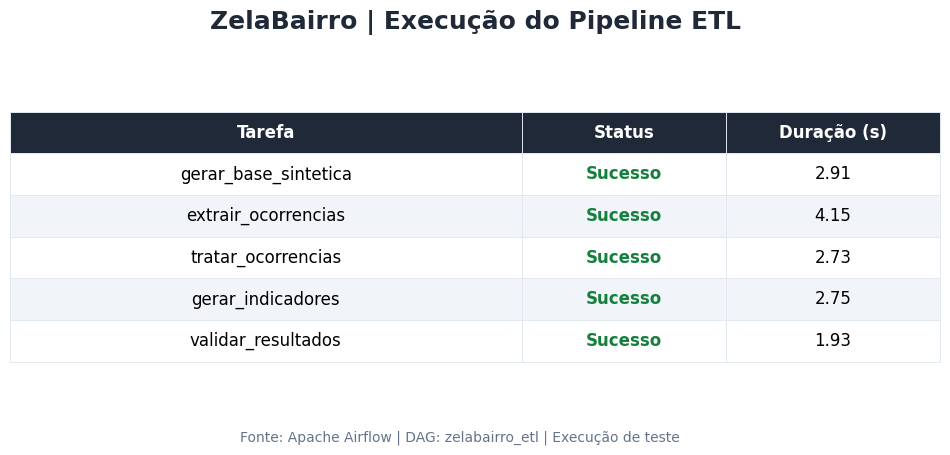

In [33]:
import matplotlib.pyplot as plt
import pandas as pd

# Organizar dados da execução
df = tarefas.copy()

df["inicio"] = pd.to_datetime(df["inicio"])
df["fim"] = pd.to_datetime(df["fim"])

df["duracao"] = (
    df["fim"] - df["inicio"]
).dt.total_seconds().round(2)

df["status"] = df["status"].replace({
    "success": "Sucesso",
    "failed": "Falha",
    "running": "Executando"
})

df = df[["tarefa", "status", "duracao"]]
df.columns = ["Tarefa", "Status", "Duração (s)"]

# Criar visualização
fig, ax = plt.subplots(figsize=(12, 4.5))
fig.patch.set_facecolor("#FFFFFF")
ax.axis("off")

ax.set_title(
    "ZelaBairro | Execução do Pipeline ETL",
    fontsize=18,
    fontweight="bold",
    color="#202938",
    pad=25
)

tabela = ax.table(
    cellText=df.values,
    colLabels=df.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.55, 0.22, 0.23]
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(12)
tabela.scale(1, 2.5)

for (linha, coluna), celula in tabela.get_celld().items():
    celula.set_edgecolor("#E2E8F0")
    celula.set_linewidth(0.7)

    if linha == 0:
        celula.set_facecolor("#202938")
        celula.set_text_props(
            color="white",
            weight="bold"
        )
    else:
        celula.set_facecolor(
            "#F1F5F9" if linha % 2 == 0 else "#FFFFFF"
        )

        if coluna == 1:
            celula.set_text_props(
                color="#15803D",
                weight="bold"
            )

plt.figtext(
    0.5, 0.04,
    "Fonte: Apache Airflow | DAG: zelabairro_etl | Execução de teste",
    ha="center",
    fontsize=10,
    color="#64748B"
)

plt.savefig(
    "ZelaBairro_Airflow_Execucao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Inspecionar o resultado *após disparar a DAG*

A célula seguinte verifica os artefatos. Um arquivo já existente pode ter sido criado pelo teste Python do bloco 3. Portanto, **somente a execução registrada no Airflow comprova a orquestração**.

In [25]:
import json
from IPython.display import display
import pandas as pd

arquivo = BASE_DIR / 'saidas' / 'indicadores.json'
if arquivo.exists():
    indicadores = json.loads(arquivo.read_text(encoding='utf-8'))
    print('Fonte:', indicadores['origem_dado'])
    print('Ocorrências:', indicadores['total_ocorrencias'])
    print('Indicadores por categoria:')
    display(pd.DataFrame(indicadores['por_categoria']))
    print('Saída para integração:', arquivo)
else:
    print('Arquivo ainda não gerado; confira a execução da DAG no Airflow.')

Fonte: sintetico
Ocorrências: 240
Indicadores por categoria:


,categoria,quantidade
0,banco,42
1,calcada,30
2,lixeira,67
3,sinalizacao,101


Saída para integração: /content/zelabairro_etapa2/saidas/indicadores.json
